In [1]:
from nasa import download_emit_ch4_filtered

search_data = True
download_data = False

if search_data: 
    download_emit_ch4_filtered(
        download_dir="./emit_ch4",
        start_date="2022-01-01",
        end_date="2025-12-31",
        bbox=  (-9, 19, 12, 38), # for algeria 
        # (5.027957, 30.72952, 7.027957, 32.72952),  # covers Nicholas study area region
        download= download_data, 
        version = "001"
        # max_results=
    )

ModuleNotFoundError: No module named 'nasa'

Note: from 13/09/ 2022 to 06/01/2022 there is no Data 

## Methane Enhancements 

In [ ]:
import os
import glob

def find_emit_files(
    base_dir,
    target_date,
    product_types=["CH4ENH", "CH4SENS", "CH4UNCERT"],
    version=None
):
    """
    Find EMIT files for a given date, product type, and optional version.

    Parameters
    ----------
    base_dir : str
        Root directory where EMIT files are stored.
    target_date : str
        Date in 'YYYYMMDD' format, e.g. '20230216'
    product_types : list
        List of product types to search (default = [CH4ENH, CH4SENS, CH4UNCERT])
    version : str or None
        Product version, e.g. "001". If None, matches any version.

    Returns
    -------
    dict
        Dictionary {product_type: [list of file paths]}
    """
    results = {}
    for ptype in product_types:
        if version:
            pattern = os.path.join(base_dir, f"**/EMIT_L2B_{ptype}_{version}_*{target_date}*.tif")
        else:
            pattern = os.path.join(base_dir, f"**/EMIT_L2B_{ptype}_*{target_date}*.tif")
        
        matches = glob.glob(pattern, recursive=True)
        results[ptype] = matches
    return results

# Example usage:
base_dir = "./emit_ch4"
target_date = "20230216"
files = find_emit_files(base_dir, target_date, version="002")

for ptype, paths in files.items():
    print(f"\n{ptype}:")
    for p in paths:
        print("  ", p)



CH4ENH:
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4ENH_002_20230216T133614_2304709_012.tif
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4ENH_002_20230216T133637_2304709_014.tif
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4ENH_002_20230216T133602_2304709_011.tif
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4ENH_002_20230216T133626_2304709_013.tif

CH4SENS:
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4SENS_002_20230216T133602_2304709_011.tif
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4SENS_002_20230216T133626_2304709_013.tif
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4SENS_002_20230216T133637_2304709_014.tif
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4SENS_002_20230216T133614_2304709_012.tif

CH4UNCERT:
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4UNCERT_002_20230216T133626_2304709_013.tif
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4UNCERT_002_20230216T133637_2304709_014.tif
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4UNCERT_002_20230216T133614_2304709_012.tif
   ./emit_ch4/EMITL2BCH4ENH/EMIT_L2B_CH4UNCERT_002_20230216T133602_2304709_0

Each scene provides three complementary rasters, which together describe the methane plume:

CH4ENH (Enhancement, ppm·m)

Unit: parts per million * meters (ppm·m).

Represents the integrated methane column enhancement along the instrument line-of-sight relative to background.

High positive values (yellow/orange) indicate strong methane plumes.

Near-zero or negative values mean no detectable plume (or possible noise).

Interpretation: This is the main methane signal product. Think of it as "how much methane is above background along the path length."

CH4SENS (Sensitivity, ppm·m)

Unit: ppm·m.

Represents the minimum detectable enhancement at each pixel given noise, surface brightness, and atmospheric conditions.

Lower values = better sensitivity (instrument is more capable of detecting plumes).

Higher values = less sensitivity (signal is noisy or surface is dark).

Interpretation: You should only trust ENH values that are significantly above SENS.

CH4UNCERT (Uncertainty, ppm·m)

Unit: ppm·m.

Per-pixel estimated retrieval uncertainty.

High values (purple/white in your map) = unreliable measurements.

Low values = more trustworthy results.

Interpretation: This helps you mask/filter ENH so that false detections (e.g., edges, clouds) are reduced.

So:
✅ CH4ENH shows the plume,
✅ CH4SENS tells you if the instrument could detect it,
✅ CH4UNCERT tells you if you should believe it

Scene 2304709_011: present=['CH4ENH', 'CH4SENS', 'CH4UNCERT'] missing=[]
   CH4ENH: v2  EMIT_L2B_CH4ENH_002_20230216T133602_2304709_011.tif
   CH4SENS: v2  EMIT_L2B_CH4SENS_002_20230216T133602_2304709_011.tif
   CH4UNCERT: v2  EMIT_L2B_CH4UNCERT_002_20230216T133602_2304709_011.tif
Scene 2304709_012: present=['CH4ENH', 'CH4SENS', 'CH4UNCERT'] missing=[]
   CH4ENH: v2  EMIT_L2B_CH4ENH_002_20230216T133614_2304709_012.tif
   CH4SENS: v2  EMIT_L2B_CH4SENS_002_20230216T133614_2304709_012.tif
   CH4UNCERT: v2  EMIT_L2B_CH4UNCERT_002_20230216T133614_2304709_012.tif
Scene 2304709_013: present=['CH4ENH', 'CH4SENS', 'CH4UNCERT'] missing=[]
   CH4ENH: v2  EMIT_L2B_CH4ENH_002_20230216T133626_2304709_013.tif
   CH4SENS: v2  EMIT_L2B_CH4SENS_002_20230216T133626_2304709_013.tif
   CH4UNCERT: v2  EMIT_L2B_CH4UNCERT_002_20230216T133626_2304709_013.tif
Scene 2304709_014: present=['CH4ENH', 'CH4SENS', 'CH4UNCERT'] missing=[]
   CH4ENH: v2  EMIT_L2B_CH4ENH_002_20230216T133637_2304709_014.tif
   CH4SENS: v2

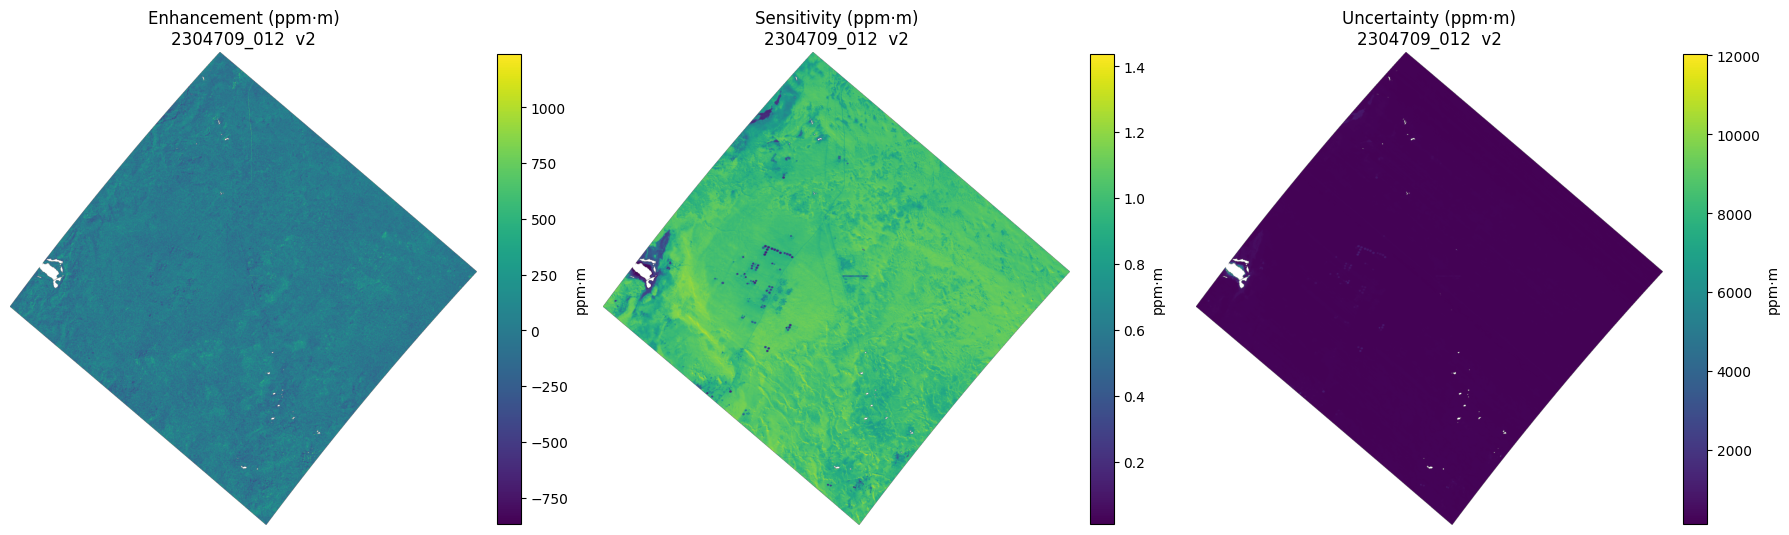

Visualizing scene 2304709_014


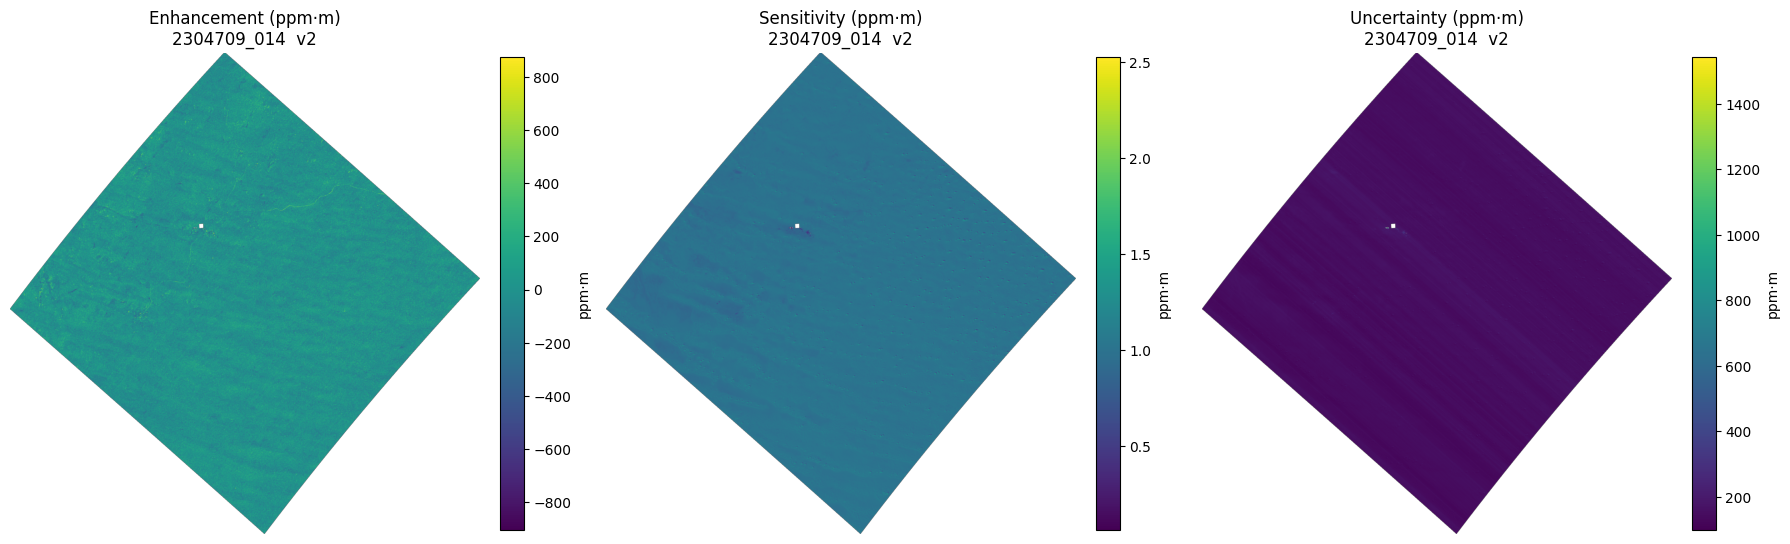

Visualizing scene 2304709_011


In [ ]:
import os
import glob
import re
from collections import defaultdict, OrderedDict
import rasterio
import numpy as np
import matplotlib.pyplot as plt


from collections import OrderedDict
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.plot import show


EMIT_REGEX = re.compile(
    r"EMIT_L2B_(CH4ENH|CH4SENS|CH4UNCERT)_(\d{3})_(\d{8}T\d{6})_(\d+_\d+)\.tif$",
    re.IGNORECASE
)

def find_and_group_emit_scenes(base_dir, target_date, version=None, prefer_latest_version=True):
    """
    Search recursively and group EMIT files by scene id.

    Parameters
    ----------
    base_dir : str
        Root folder with downloaded EMIT tif files.
    target_date : str
        Date string 'YYYYMMDD' to filter files, e.g. '20230216'.
    version : str or None
        If provided (e.g. "002"), only consider files of that version.
    prefer_latest_version : bool
        If True, keeps the file with the largest version number when
        multiple versions exist for same (scene, product).

    Returns
    -------
    dict
        { scene_id : { 'CH4ENH': {'path':..., 'version':int, 'datetime':...}, 
                       'CH4SENS': {...},
                       'CH4UNCERT': {...} } }
    """
    # Build search glob pattern (catch all CH4 products if version is None)
    if version:
        pattern = os.path.join(base_dir, f"**/EMIT_L2B_CH4*_{version}_*{target_date}*.tif")
    else:
        pattern = os.path.join(base_dir, f"**/EMIT_L2B_CH4*_*{target_date}*.tif")

    files = glob.glob(pattern, recursive=True)
    scenes = defaultdict(dict)

    for fp in files:
        fname = os.path.basename(fp)
        m = EMIT_REGEX.search(fname)
        if not m:
            # if filename doesn't match exact pattern, skip (or log)
            # you can print(fname) for debugging
            continue

        product, ver_str, dtstamp, scene_id = m.groups()
        ver = int(ver_str)
        product = product.upper()  # e.g. CH4ENH

        # If version filter provided but doesn't match (defensive)
        if version and ver_str != version:
            continue

        # Keep only the highest version per (scene, product) if requested
        existing = scenes[scene_id].get(product)
        if existing is None:
            scenes[scene_id][product] = {"path": fp, "version": ver, "datetime": dtstamp}
        else:
            if prefer_latest_version and ver > existing["version"]:
                scenes[scene_id][product] = {"path": fp, "version": ver, "datetime": dtstamp}
            # else keep existing

    # Return normal dict (not defaultdict)
    return dict(scenes)


def print_scene_summary(scenes):
    """Print a simple summary of found scenes and which products are present."""
    for sid in sorted(scenes.keys()):
        products = scenes[sid]
        present = sorted([k for k in products.keys()])
        missing = [k for k in ("CH4ENH", "CH4SENS", "CH4UNCERT") if k not in products]
        print(f"Scene {sid}: present={present} missing={missing}")
        for k in present:
            info = products[k]
            print(f"   {k}: v{info['version']}  {os.path.basename(info['path'])}")
    if not scenes:
        print("No scenes found.")


def visualize_scene(scene_record, scene_id, vmin=None, vmax=None, cmap="viridis"):
    """
    Plot ENH / SENS / UNCERT side-by-side for one scene_record (dict of product->info).
    scene_record example: {'CH4ENH': {'path':..., 'version':...}, ...}
    """
    required = ["CH4ENH", "CH4SENS", "CH4UNCERT"]
    missing = [r for r in required if r not in scene_record]
    if missing:
        raise ValueError(f"Cannot visualize scene {scene_id}: missing products {missing}")

    # Order panels: ENH, SENS, UNCERT
    ordered = OrderedDict([
        ("CH4ENH", "Enhancement (ppm·m)"),
        ("CH4SENS", "Sensitivity (ppm·m)"),
        ("CH4UNCERT", "Uncertainty (ppm·m)")
    ])

    fig, axs = plt.subplots(1, 3, figsize=(18, 6))
    for ax, (prod_key, title) in zip(axs, ordered.items()):
        path = scene_record[prod_key]["path"]
        with rasterio.open(path) as src:
            arr = src.read(1).astype(np.float32)
            # Mask nodata values (if present)
            if src.nodata is not None:
                arr = np.where(arr == src.nodata, np.nan, arr)

            # plot using rasterio.show() to respect georeferencing
            show(
                arr,
                transform=src.transform,
                ax=ax,
                cmap=cmap,
                vmin=vmin,
                vmax=vmax
            )

            ax.set_title(f"{title}\n{scene_id}  v{scene_record[prod_key]['version']}")
            ax.axis("off")
            plt.colorbar(
                ax.images[0], ax=ax, fraction=0.046, pad=0.04, label="ppm·m"
            )

    plt.tight_layout()
    plt.show()

base_dir = "./emit_ch4"
target_date = "20230216"   # YYYYMMDD
version = "002"          # optionally set to "001" or "002"
scenes = find_and_group_emit_scenes(base_dir, target_date, version=version, prefer_latest_version=True)

print_scene_summary(scenes)

# Visualize all scenes that have all 3 products
for scene_id, rec in scenes.items():
    if all(k in rec for k in ("CH4ENH", "CH4SENS", "CH4UNCERT")):
        print(f"Visualizing scene {scene_id}")
        visualize_scene(rec, scene_id)
    else:
        print(f"Skipping scene {scene_id} (incomplete files)")


## PLumes Complexe

### Visualize one plume complexe

In [ ]:
import rasterio
import matplotlib.pyplot as plt
import json
import geopandas as gpd
from rasterio.plot import show
from shapely.geometry import box

def visualize_plume_complex(tif_path, json_path):
    # --- Load raster ---
    with rasterio.open(tif_path) as src:
        data = src.read(1)  # first band
        bounds = src.bounds
        crs = src.crs

    # --- Plot raster ---
    fig, ax = plt.subplots(figsize=(8, 6))
    show(data, transform=src.transform, ax=ax, cmap="inferno")
    ax.set_title(f"Plume Complex: {tif_path}")

    # --- Plot bounding box (optional) ---
    gdf = gpd.GeoDataFrame(
        {"geometry": [box(*bounds)]}, crs=crs
    )
    gdf.boundary.plot(ax=ax, color="blue")

    plt.show()

    # --- Load metadata ---
    with open(json_path, "r") as f:
        metadata = json.load(f)

    print("\n--- Metadata Summary ---")
    for k, v in metadata.items():
        print(f"{k}: {v}")


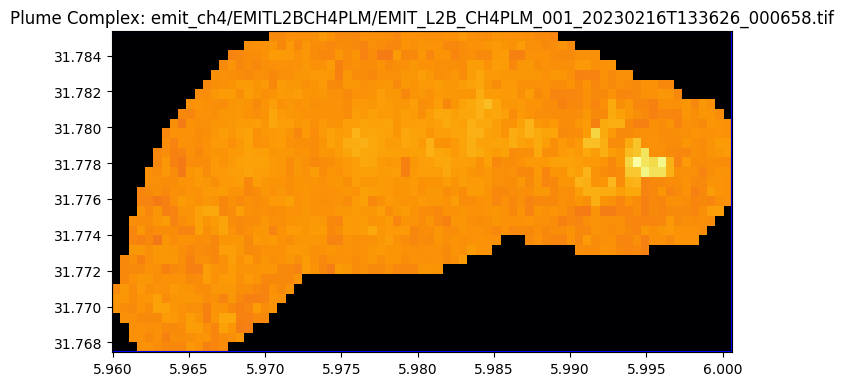


--- Metadata Summary ---
crs: {'properties': {'name': 'urn:ogc:def:crs:OGC:1.3:CRS84'}, 'type': 'name'}
features: [{'geometry': {'coordinates': [[[5.9713305, 31.7853466], [5.9675349, 31.7842621], [5.9637393, 31.7804665], [5.9615704, 31.7761286], [5.9599437, 31.7701641], [5.9621126, 31.7669107], [5.9659082, 31.7669107], [5.9707883, 31.7696218], [5.972415, 31.7717908], [5.9805485, 31.7717908], [5.9843441, 31.7728752], [5.9854286, 31.7739597], [5.9919354, 31.7728752], [5.9978999, 31.7734175], [6.0006111, 31.7755864], [6.0011533, 31.7772131], [6.0011533, 31.779382], [5.9989844, 31.781551], [5.9973577, 31.781551], [5.9962732, 31.7826354], [5.9946465, 31.7826354], [5.988682, 31.7853466], [5.9713305, 31.7853466]]], 'type': 'Polygon'}, 'properties': {'Concentration Uncertainty (ppm m)': 339.0, 'DAAC Scene Numbers': ['013'], 'DCID': '1360369824', 'Latitude of max concentration': 31.77802644428709, 'Longitude of max concentration': 5.994375425173483, 'Max Plume Concentration (ppm m)': 3301.0, '

In [ ]:
visualize_plume_complex(
    "emit_ch4/EMITL2BCH4PLM/EMIT_L2B_CH4PLM_001_20230216T133626_000658.tif",
    "emit_ch4/EMITL2BCH4PLM/EMIT_L2B_CH4PLMMETA_001_20230216T133626_000658.json"
)


### Visualize multiple Plume complexes

In [ ]:
import os
import glob
import rasterio
import json
import matplotlib.pyplot as plt

def visualize_ch4plm_products(base_dir, date=None, version=None):
    """
    Visualize EMIT CH4PLM plume complexes (TIFF + JSON).
    
    Parameters:
        base_dir (str): Directory containing CH4PLM files
        date (str, optional): Date in format YYYYMMDD to filter (default: None = all dates)
        version (str, optional): Version string like '001' (default: None = all versions)
    """
    # Build pattern for TIFF files
    tiff_pattern = os.path.join(base_dir, "EMIT_L2B_CH4PLM_*.tif")
    json_pattern = os.path.join(base_dir, "EMIT_L2B_CH4PLMMETA_*.json")
    
    tiff_files = glob.glob(tiff_pattern)
    json_files = glob.glob(json_pattern)

    # Apply filters
    if date:
        tiff_files = [f for f in tiff_files if f"_{date}" in f]
        json_files = [f for f in json_files if f"_{date}" in f]
    if version:
        tiff_files = [f for f in tiff_files if f"_{version}_" in f]
        json_files = [f for f in json_files if f"_{version}_" in f]

    # Group files by plume identifier (last 6 digits before extension)
    plumes = {}
    for tiff in tiff_files:
        plume_id = os.path.basename(tiff).split("_")[-1].replace(".tif", "")
        plumes.setdefault(plume_id, {})["tif"] = tiff
    for js in json_files:
        plume_id = os.path.basename(js).split("_")[-1].replace(".json", "")
        plumes.setdefault(plume_id, {})["json"] = js

    # Visualize each plume
    for plume_id, files in plumes.items():
        if "tif" not in files or "json" not in files:
            continue

        print(f"\nPlume ID: {plume_id}")
        print(f"  TIFF: {files['tif']}")
        print(f"  JSON: {files['json']}")

        # Load raster
        with rasterio.open(files["tif"]) as src:
            img = src.read(1)
            plt.figure(figsize=(6, 5))
            plt.imshow(img, cmap="viridis")
            plt.colorbar(label="CH₄ Enhancement")
            plt.title(f"Plume Complex {plume_id} ({date})")
            plt.xlabel("X pixels")
            plt.ylabel("Y pixels")
            plt.show()

        # Load JSON metadata
        with open(files["json"], "r") as f:
            metadata = json.load(f)

        print("Metadata Summary:")
        for key, val in metadata.items():
            print(f"  {key}: {val}")



Plume ID: 001687
  TIFF: emit_ch4/EMITL2BCH4PLM/EMIT_L2B_CH4PLM_001_20230929T122534_001687.tif
  JSON: emit_ch4/EMITL2BCH4PLM/EMIT_L2B_CH4PLMMETA_001_20230929T122534_001687.json


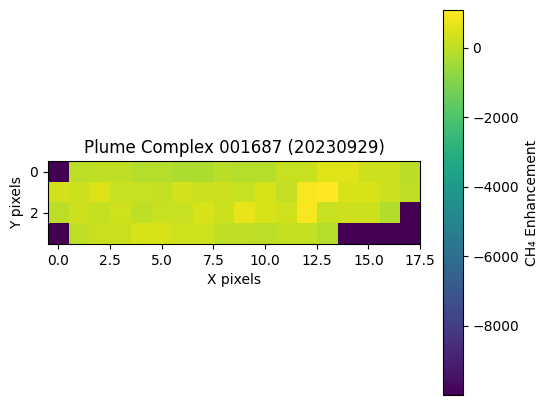

Metadata Summary:
  crs: {'properties': {'name': 'urn:ogc:def:crs:OGC:1.3:CRS84'}, 'type': 'name'}
  features: [{'geometry': {'coordinates': [[[6.2072017, 31.7831777], [6.2061172, 31.7820932], [6.2077439, 31.7804665], [6.2115395, 31.7804665], [6.2169619, 31.7820932], [6.2169619, 31.7831777], [6.2072017, 31.7831777]]], 'type': 'Polygon'}, 'properties': {'Concentration Uncertainty (ppm m)': 276.0, 'DAAC Scene Numbers': ['039'], 'DCID': '1379881604', 'Latitude of max concentration': 31.78236430444919, 'Longitude of max concentration': 6.213979595877308, 'Max Plume Concentration (ppm m)': 1080.0, 'Orbit': '2327208', 'Plume ID': 'CH4_PlumeComplex-1687', 'Scene FIDs': ['emit20230929t122534'], 'UTC Time Observed': '2023-09-29T12:25:34Z', 'map_endtime': '2023-09-29T12:25:35Z', 'DAAC Scene Names': ['EMIT_L2B_CH4ENH_V001_20230929T122534_2327208_039']}, 'type': 'Feature'}]
  name: methane_metadata
  type: FeatureCollection

Plume ID: 001683
  TIFF: emit_ch4/EMITL2BCH4PLM/EMIT_L2B_CH4PLM_001_20230

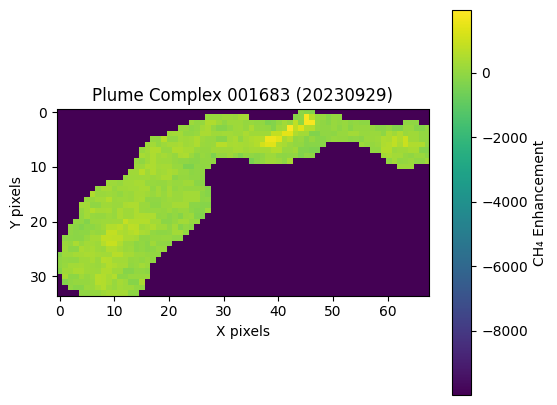

Metadata Summary:
  crs: {'properties': {'name': 'urn:ogc:def:crs:OGC:1.3:CRS84'}, 'type': 'name'}
  features: [{'geometry': {'coordinates': [[[5.9946465, 31.779382], [5.9935621, 31.7782976], [5.9859708, 31.7788398], [5.979464, 31.7761286], [5.9778373, 31.7728752], [5.9745839, 31.7717908], [5.9729572, 31.7701641], [5.9729572, 31.7685374], [5.9718728, 31.7679951], [5.9707883, 31.7641995], [5.9713305, 31.7620306], [5.9745839, 31.7604039], [5.9789218, 31.7609461], [5.9805485, 31.7647417], [5.9854286, 31.7685374], [5.9859708, 31.7701641], [5.9854286, 31.7734175], [5.9865131, 31.7745019], [5.9924776, 31.7739597], [5.995731, 31.7745019], [5.9973577, 31.7761286], [6.0000689, 31.7761286], [6.004949, 31.7734175], [6.0082024, 31.7745019], [6.0082024, 31.7772131], [6.0060334, 31.7782976], [6.0033223, 31.7777553], [5.9946465, 31.779382]]], 'type': 'Polygon'}, 'properties': {'Concentration Uncertainty (ppm m)': 322.0, 'DAAC Scene Numbers': ['039'], 'DCID': '1379881604', 'Latitude of max concentrati

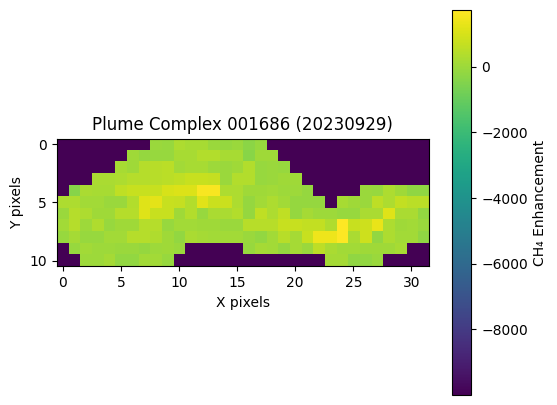

Metadata Summary:
  crs: {'properties': {'name': 'urn:ogc:def:crs:OGC:1.3:CRS84'}, 'type': 'name'}
  features: [{'geometry': {'coordinates': [[[6.0082024, 31.5646579], [6.0033223, 31.5619468], [6.0033223, 31.5597779], [6.004949, 31.5581512], [6.0076601, 31.5581512], [6.0098291, 31.5597779], [6.0179625, 31.5586934], [6.0212159, 31.5603201], [6.0206737, 31.562489], [6.0179625, 31.562489], [6.0157936, 31.5614046], [6.0125402, 31.5646579], [6.0082024, 31.5646579]]], 'type': 'Polygon'}, 'properties': {'Concentration Uncertainty (ppm m)': 380.0, 'DAAC Scene Numbers': ['039'], 'DCID': '1379881604', 'Latitude of max concentration': 31.560591203664334, 'Longitude of max concentration': 6.01660695850399, 'Max Plume Concentration (ppm m)': 1725.0, 'Orbit': '2327208', 'Plume ID': 'CH4_PlumeComplex-1686', 'Scene FIDs': ['emit20230929t122534'], 'UTC Time Observed': '2023-09-29T12:25:34Z', 'map_endtime': '2023-09-29T12:25:35Z', 'DAAC Scene Names': ['EMIT_L2B_CH4ENH_V001_20230929T122534_2327208_039']}

In [ ]:
visualize_ch4plm_products("emit_ch4/EMITL2BCH4PLM", date="20230929", version="001")

/tmp/ipykernel_85575/1610000330.py:81: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  mpl_cmap = cm.get_cmap("viridis")



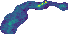

In [2]:
import os, json
import numpy as np
import rasterio
import folium
from glob import glob
from folium.raster_layers import ImageOverlay
from branca.colormap import LinearColormap
from matplotlib import cm, colors


def _extract_plume_id(path):
    """Helper: extract plume ID (last 6 digits before extension)."""
    return os.path.basename(path).split("_")[-1].split(".")[0]


def _bounds_from_raster(src):
    """Return [[south, west], [north, east]] for Folium."""
    b = src.bounds
    return [[b.bottom, b.left], [b.top, b.right]]


def visualize_plume_complexes_overlay(
    base_dir,
    date=None,
    version=None,
    opacity=0.7,
    legend_label="CH₄ enhancement (ppm·m)"
):
    """
    Overlay CH4PLM rasters under plume polygons (metadata GeoJSON) on an interactive Folium map.
    """

    # ---- 1) Collect files ----
    tiffs = sorted(glob(os.path.join(base_dir, "EMIT_L2B_CH4PLM_*.tif")))
    metas = sorted(glob(os.path.join(base_dir, "EMIT_L2B_CH4PLMMETA_*.json")))

    if date:
        tiffs = [p for p in tiffs if f"_{date}" in p]
        metas = [p for p in metas if f"_{date}" in p]
    if version:
        tiffs = [p for p in tiffs if f"_{version}_" in p]
        metas = [p for p in metas if f"_{version}_" in p]

    # Pair by plume ID
    by_id = {}
    for p in tiffs:
        by_id.setdefault(_extract_plume_id(p), {}).update(tif=p)
    for p in metas:
        by_id.setdefault(_extract_plume_id(p), {}).update(json=p)

    pairs = {pid: f for pid, f in by_id.items() if "tif" in f and "json" in f}
    if not pairs:
        print("No matched TIFF+JSON plume pairs found.")
        return None

    # ---- 2) Global min/max ----
    global_min, global_max = np.inf, -np.inf
    for pid, files in pairs.items():
        with rasterio.open(files["tif"]) as src:
            arr = src.read(1).astype("float32")
            nodata = src.nodata
            if nodata is not None:
                arr = np.where(arr == nodata, np.nan, arr)
            if np.isfinite(arr).any():
                global_min = min(global_min, np.nanmin(arr))
                global_max = max(global_max, np.nanmax(arr))

    if not np.isfinite(global_min) or not np.isfinite(global_max) or global_min == global_max:
        global_min, global_max = 0.0, 1.0

    def _normalize(arr):
        return np.clip((arr - global_min) / (global_max - global_min), 0, 1)

    # For legend
    legend_cmap = LinearColormap(
        colors=["#440154", "#3B528B", "#21918C", "#5EC962", "#FDE725"],
        vmin=global_min, vmax=global_max
    )

    # For raster overlay: use matplotlib colormap
    mpl_cmap = cm.get_cmap("viridis")

    # ---- 3) Initialize map ----
    first_json = next(iter(pairs.values()))["json"]
    with open(first_json, "r") as f:
        gj = json.load(f)
    coords = gj["features"][0]["geometry"]["coordinates"]
    gtype = gj["features"][0]["geometry"]["type"]
    if gtype == "Polygon":
        lon, lat = coords[0][0]
    elif gtype == "MultiPolygon":
        lon, lat = coords[0][0][0]
    elif gtype == "Point":
        lon, lat = coords
    else:
        lon, lat = coords[0]
    fmap = folium.Map(location=[lat, lon], zoom_start=8, control_scale=True)

    # ---- 4) Add plume layers ----
    for pid, files in sorted(pairs.items()):
        layer = folium.FeatureGroup(name=f"Plume {pid}", show=True)

        # Raster overlay
        with rasterio.open(files["tif"]) as src:
            arr = src.read(1).astype("float32")
            nodata = src.nodata
            if nodata is not None:
                arr = np.where(arr == nodata, np.nan, arr)

            norm = _normalize(arr)

            # Apply colormap → RGBA 0-255
            rgba = (mpl_cmap(norm) * 255).astype(np.uint8)

            # Folium expects (H, W, 4)
            bounds = _bounds_from_raster(src)
            ImageOverlay(
                image=rgba,
                bounds=bounds,
                opacity=opacity,
                name=f"Raster {pid}",
            ).add_to(layer)

        # Polygon overlay
        with open(files["json"], "r") as f:
            gj = json.load(f)
        folium.GeoJson(
            data=gj,
            name=f"Polygon {pid}",
            tooltip=folium.GeoJsonTooltip(fields=list(gj["features"][0].get("properties", {}).keys())),
            style_function=lambda _: {
                "color": "#FFFF00",
                "weight": 2,
                "fillOpacity": 0.0,
            },
            highlight_function=lambda _: {"weight": 3},
        ).add_to(layer)

        layer.add_to(fmap)

    # ---- 5) Legend + controls ----
    legend_cmap.caption = legend_label
    legend_cmap.add_to(fmap)
    folium.LayerControl(collapsed=False).add_to(fmap)

    return fmap

# ---------- Example ----------
m = visualize_plume_complexes_overlay(
    base_dir="emit_ch4/EMITL2BCH4PLM",
    version="001",
    date="20230929",
    opacity=0.75,
    legend_label="EMIT CH₄ plume (ppm·m)"
)
# m.save("plumes_overlay.html")  # open in your browser
m  # if you're in a notebook
